# Face Recognition Assignment




# Task 1

faces_assignment klasöründe yer alan resimlerin hepsi için age, gender, race ve emotion tespiti yapınız.

- age'i olduğu gibi kullanınız
- gender için dominat_gender'ı kullanınız
- race için dominant race'ı kullanınız
- emotion için dominant_emotion'ı kullanınız


Çıktıda file_name (yani geziyor olduğunuz dizin bilgisi), age, gender, race ve emotion olmalı.

örnek çıktı şu şekilde olmalı:



```
 [{'file_name': '/content/faces_lectures/face18.png',
  'age': 28,
  'gender': 'Man',
  'race': 'white',
  'emotion': 'sad'},
 {'file_name': '/content/faces_lectures/face16.png',
  'age': 45,
  'gender': 'Man',
  'race': 'white',
  'emotion': 'happy'},
 {'file_name': '/content/faces_lectures/face17.png',
  'age': 31,
  'gender': 'Woman',
  'race': 'asian',
  'emotion': 'happy'},
 {'file_name': '/content/faces_lectures/face19.png',
  'age': 22,
  'gender': 'Man',
  'race': 'asian',
  'emotion': 'happy'},
 {'file_name': '/content/faces_lectures/face20.png',
  'age': 26,
  'gender': 'Woman',
  'race': 'asian',
  'emotion': 'neutral'}]
```




  Dikkat edilmesi gerekenler:

  - Tüm işlemleri tek bir fonksiyon yapmalı. fonksiyona sadece root_path yani resimlerin olduğu dizin girilmeli.

  - Amelasyon olmamalı, bunun için path'leri gezecek bir döngü ve oluşturulması gerek ve tüm result'ları tutacak olan results'u gezecek olan bir döngü olmalı.

  - Sonuçlar return edilmeli.

# Task 1 Solution

In [3]:
!pip install deepface

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 286.6/286.6 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 50.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.5/69.5 MB 11.7 MB/s eta 0:00:00


In [4]:
from deepface import DeepFace
import os
import pandas as pd
import cv2
import matplotlib.pyplot as plt

26-10-17 17:27:58 - Directory /root/.deepface has been created
26-10-17 17:27:58 - Directory /root/.deepface/weights has been created


In [13]:
#img_path = "faces_assignment/face4.png"
images_path = "faces_assignment"

In [14]:
image_paths = [os.path.join(images_path, f) for f in os.listdir(images_path) if f.endswith(('.jpg', '.jpeg', '.png'))]

In [15]:
image_paths

['faces_assignment/face1.png',
 'faces_assignment/face2.png',
 'faces_assignment/face4.png',
 'faces_assignment/face5.png',
 'faces_assignment/face3.png']

In [19]:
output_list = []

for path in image_paths:
    # DeepFace.analyze bir liste döndürür, bu yüzden ilk yüz için [0] kullanılır
    analysis = DeepFace.analyze(
        path, actions=["age", "gender", "race", "emotion"], enforce_detection=False
    )

    # Eğer sonuç liste ise ilk elemanı alalım
    res = analysis[0] if isinstance(analysis, list) else analysis

    # İstenen formata uygun sözlüğü oluşturalım
    file_info = {
        "file_name": path,  # veya tam yol için: os.path.abspath(path)
        "age": res.get("age"),
        "gender": res.get("dominant_gender"),
        "race": res.get("dominant_race"),
        "emotion": res.get("dominant_emotion"),
    }

    output_list.append(file_info)

Action: emotion: 100%|██████████| 4/4 [00:01<00:00,  2.07it/s]


In [20]:
output_list

[{'file_name': 'faces_assignment/face1.png',
  'age': 35,
  'gender': 'Woman',
  'race': 'white',
  'emotion': 'fear'},
 {'file_name': 'faces_assignment/face2.png',
  'age': 23,
  'gender': 'Woman',
  'race': 'white',
  'emotion': 'happy'},
 {'file_name': 'faces_assignment/face4.png',
  'age': 27,
  'gender': 'Man',
  'race': 'white',
  'emotion': 'happy'},
 {'file_name': 'faces_assignment/face5.png',
  'age': 25,
  'gender': 'Man',
  'race': 'middle eastern',
  'emotion': 'happy'},
 {'file_name': 'faces_assignment/face3.png',
  'age': 30,
  'gender': 'Woman',
  'race': 'white',
  'emotion': 'happy'}]

# Task 2

Önceki bölümdeki fonksiyonun çıktısını tutarak bu çıktıdaki bilgileri resimlerin üzerine yazdırınız.

Önce tek bir görsel için yapınız daha sonra bir dizindeki tüm görseller için yapınız.

Fonksiyonun adı visualize_all_attribute olmalı.

İpucları:

- Fonksiyon iki argumana sahip olmalı: img_path, result

- Adı visualize_all_attribute olmalı.

- Dersteki if else bloğuna gerek yok.

- Sadece title bölümüne odaklanıp bilgiler title'a yansıtmalı. Yani age, gender, race, emotion bilgileri resmin kendisinin üzerine değil uygulamamızdaki gibi olmalı.


# Task 2 Solution



In [21]:
def visualize_all_attribute(img_path, result):

    image = cv2.imread(img_path)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # result bir liste ise ilk yüzün verisini alıyoruz
    res = result[0] if isinstance(result, list) else result

    # İstenen nitelikleri result sözlüğünden çekiyoruz
    age = res.get("age")
    gender = res.get("dominant_gender")
    race = res.get("dominant_race")
    emotion = res.get("dominant_emotion")

    # Title için metni oluşturuyoruz
    title_text = f"Age: {age} | Gender: {gender} | Race: {race} | Emotion: {emotion}"

    # Görseli çizdirme ve title ekleme
    plt.figure(figsize=(6, 6))
    plt.imshow(image_rgb)
    plt.axis("off")
    plt.title(title_text, fontsize=12)
    plt.show()

Action: emotion: 100%|██████████| 4/4 [00:03<00:00,  1.20it/s]


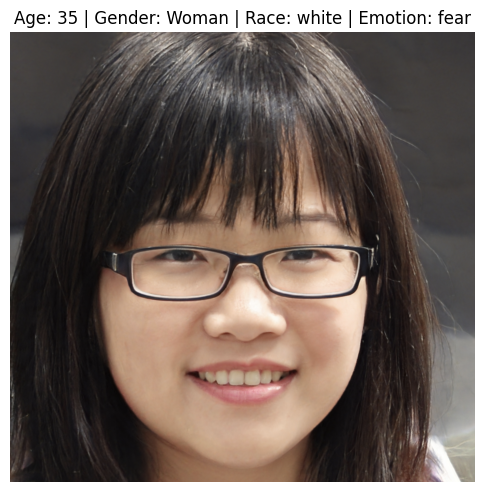

Action: emotion: 100%|██████████| 4/4 [00:01<00:00,  2.03it/s]


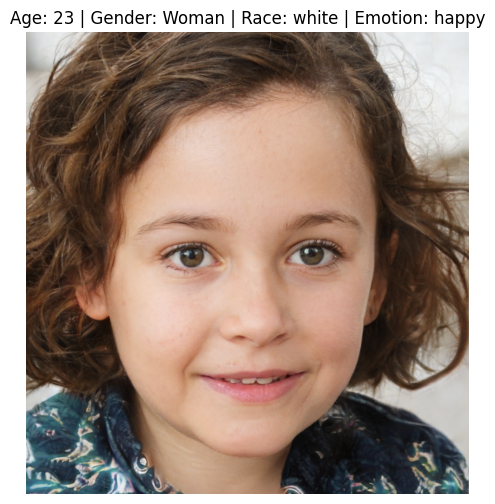

Action: emotion: 100%|██████████| 4/4 [00:03<00:00,  1.25it/s]


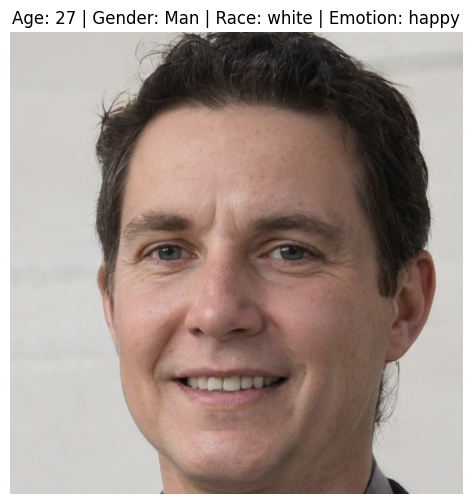

Action: emotion: 100%|██████████| 4/4 [00:01<00:00,  2.01it/s]


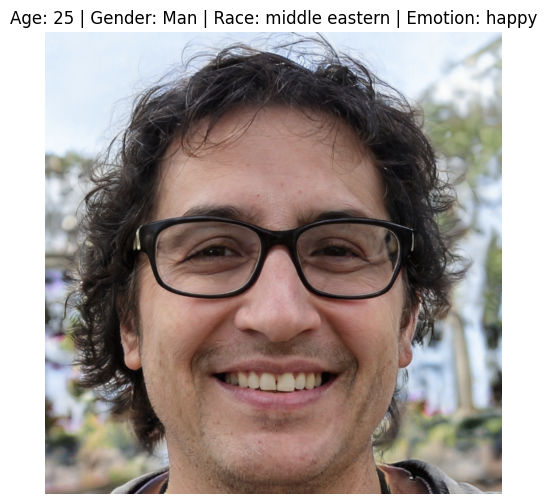

Action: emotion: 100%|██████████| 4/4 [00:03<00:00,  1.21it/s]


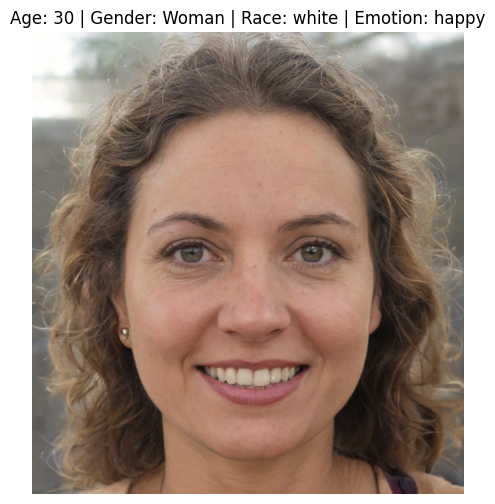

In [22]:
import os
from deepface import DeepFace

images_path = "faces_assignment"  # Ödevdeki klasör yolunuz
image_paths = [
    os.path.join(images_path, f)
    for f in os.listdir(images_path)
    if f.endswith((".jpg", ".jpeg", ".png"))
]

for path in image_paths:
  # 1. DeepFace ile analiz yap
  analysis_result = DeepFace.analyze(
      path, actions=["age", "gender", "race", "emotion"], enforce_detection=False
  )

  # 2. Fonksiyonu çağırarak başlıkta göster
  visualize_all_attribute(path, analysis_result)